In [17]:
!nvidia-smi
!pip -q install ultralytics onnx onnxruntime-gpu fastapi "uvicorn[standard]" nest_asyncio

Tue Oct 27 14:38:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P0             31W /   70W |     231MiB /  15360MiB |     14%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [18]:
import subprocess, os, time

# Download the latest MediaMTX Linux build
url = !curl -s https://api.github.com/repos/bluenviron/mediamtx/releases/latest | grep browser_download_url | grep linux_amd64.tar.gz | cut -d '"' -f 4
print("Downloading:", url[0])
!wget -q {url[0]} -O /content/mediamtx.tar.gz
!cd /content && tar -xzf mediamtx.tar.gz mediamtx mediamtx.yml

# Start the RTSP server in the background
mtx = subprocess.Popen(["/content/mediamtx", "/content/mediamtx.yml"],
                       stdout=open("/content/mediamtx.log", "w"),
                       stderr=subprocess.STDOUT)
time.sleep(2)
print("MediaMTX running:", mtx.poll() is None)

Downloading: https://github.com/bluenviron/mediamtx/releases/download/v1.21.3/mediamtx_v1.21.3_linux_amd64.tar.gz
MediaMTX running: False


In [19]:
import subprocess, time, os

assert os.path.exists("/content/sample.mp4"), "Upload sample.mp4 to /content first"
subprocess.run(["pkill", "-x", "ffmpeg"]); time.sleep(1)

# One-time: 20 s, 720p, 15 fps, short GOP, no B-frames
if not os.path.exists("/content/sample_720.mp4"):
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "/content/sample.mp4", "-t", "20",
                    "-vf", "scale=1280:720", "-r", "15", "-c:v", "libx264", "-preset", "veryfast",
                    "-crf", "23", "-g", "30", "-bf", "0", "-pix_fmt", "yuv420p", "-an",
                    "/content/sample_720.mp4"], check=True)

# Stream with NO re-encoding, like a camera that encodes in hardware
ff = subprocess.Popen(["ffmpeg", "-re", "-stream_loop", "-1", "-i", "/content/sample_720.mp4",
                       "-c", "copy", "-f", "rtsp", "-rtsp_transport", "tcp",
                       "rtsp://localhost:8554/cam1"],
                      stdout=subprocess.DEVNULL, stderr=open("/content/ffmpeg.log", "w"))
time.sleep(4)
print("camera running:", ff.poll() is None)

camera running: True


Opened: True | Frame read: True | Shape: (720, 1280, 3)


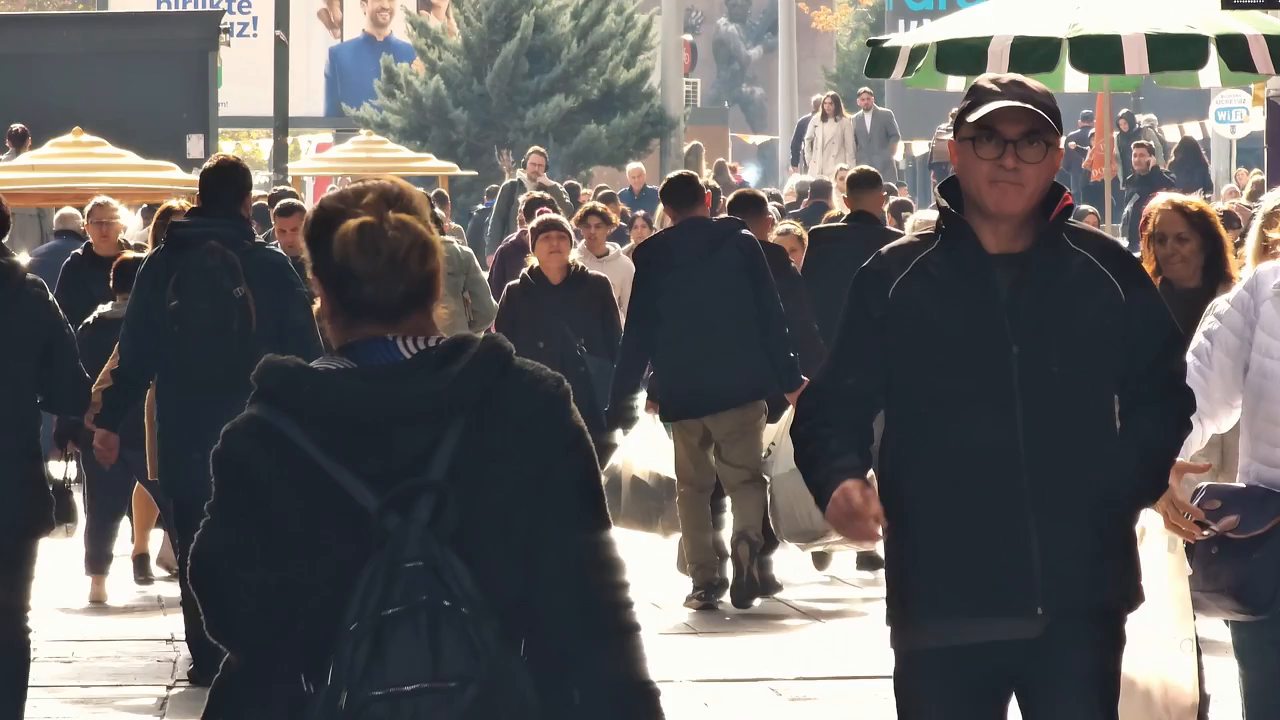

In [20]:
os.environ["OPENCV_FFMPEG_CAPTURE_OPTIONS"] = "rtsp_transport;tcp"
import cv2
from google.colab.patches import cv2_imshow

cap = cv2.VideoCapture("rtsp://localhost:8554/cam1", cv2.CAP_FFMPEG)
ok, frame = cap.read()
print("Opened:", cap.isOpened(), "| Frame read:", ok, "| Shape:", frame.shape if ok else None)
if ok:
    cv2_imshow(frame)
cap.release()

In [21]:
import threading, time, cv2, numpy as np, torch
from ultralytics import YOLO
from google.colab.patches import cv2_imshow

class RTSPReader:
    def __init__(self, url):
        self.url, self.frame, self.ts = url, None, 0.0
        self.lock = threading.Lock()
        self.running, self.connected = True, False
        self.frames_read, self.reconnects = 0, 0
        threading.Thread(target=self._loop, daemon=True).start()

    def _loop(self):
        while self.running:
            cap = cv2.VideoCapture(self.url, cv2.CAP_FFMPEG)
            if not cap.isOpened():
                time.sleep(2); continue
            self.connected = True
            while self.running:
                ok, f = cap.read()
                if not ok:
                    break
                with self.lock:
                    self.frame, self.ts = f, time.time()
                    self.frames_read += 1
            cap.release()
            self.connected = False
            self.reconnects += 1
            time.sleep(1)

    def latest(self):
        with self.lock:
            return (None, 0.0) if self.frame is None else (self.frame.copy(), self.ts)

    def stop(self):
        self.running = False

device                       cuda
frames_read_from_stream      480
frames_processed             448
frames_skipped_by_design     32
avg_fps                      14.93
infer_ms_p50                 34.6
infer_ms_p95                 42.1
e2e_latency_ms_p50           37.2
unique_track_ids             173
peak_gpu_mem_MB              66.1
reader_reconnects            0


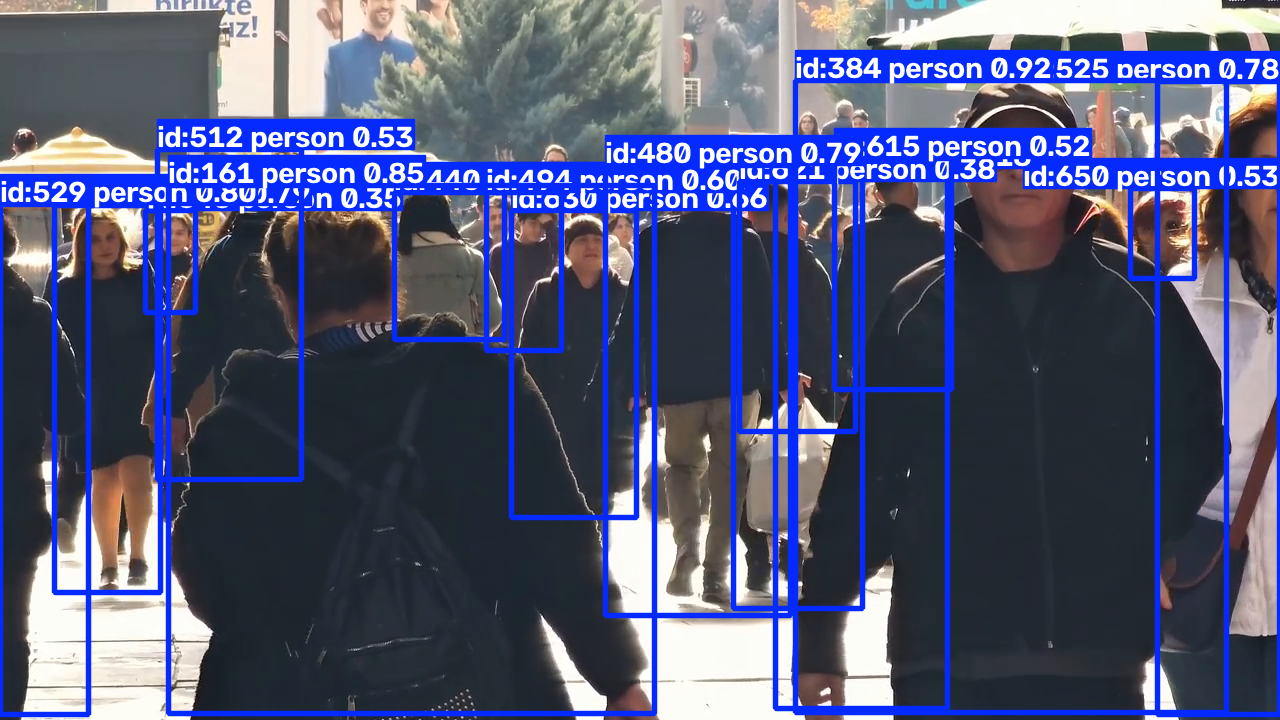

In [22]:
def run_pipeline(url="rtsp://localhost:8554/cam1", seconds=30, weights="yolov8n.pt", imgsz=640, annotate_every=3):
    model = YOLO(weights)
    model.predict(np.zeros((720, 1280, 3), np.uint8), imgsz=imgsz, verbose=False)  # warm-up

    reader = RTSPReader(url)
    while reader.frame is None:
        time.sleep(0.1)

    writer = cv2.VideoWriter("/content/annotated.mp4", cv2.VideoWriter_fourcc(*"mp4v"), 15 // annotate_every, (1280, 720))
    infer_ms, e2e_ms, ids_seen = [], [], set()
    processed, last_ts, last_plot = 0, 0.0, None
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    t0 = time.time()
    while time.time() - t0 < seconds:
        frame, ts = reader.latest()
        if frame is None or ts == last_ts:
            time.sleep(0.002); continue
        last_ts = ts

        t1 = time.time()
        res = model.track(frame, tracker="bytetrack.yaml", persist=True, imgsz=imgsz,
                          classes=[0, 1, 2, 3, 5, 7], verbose=False)[0]
        t2 = time.time()

        infer_ms.append((t2 - t1) * 1000)
        e2e_ms.append((t2 - ts) * 1000)
        processed += 1
        if res.boxes.id is not None:
            ids_seen.update(res.boxes.id.int().tolist())

        if processed % annotate_every == 0:
            last_plot = res.plot()
            writer.write(last_plot)

    elapsed = time.time() - t0
    reader.stop(); writer.release()

    return {
        "device": "cuda" if torch.cuda.is_available() else "cpu",
        "frames_read_from_stream": reader.frames_read,
        "frames_processed": processed,
        "frames_skipped_by_design": reader.frames_read - processed,
        "avg_fps": round(processed / elapsed, 2),
        "infer_ms_p50": round(float(np.percentile(infer_ms, 50)), 1),
        "infer_ms_p95": round(float(np.percentile(infer_ms, 95)), 1),
        "e2e_latency_ms_p50": round(float(np.percentile(e2e_ms, 50)), 1),
        "unique_track_ids": len(ids_seen),
        "peak_gpu_mem_MB": round(torch.cuda.max_memory_allocated() / 1e6, 1) if torch.cuda.is_available() else None,
        "reader_reconnects": reader.reconnects,
    }, last_plot

stats, last = run_pipeline(seconds=30)
for k, v in stats.items():
    print(f"{k:28s} {v}")
cv2_imshow(last)

In [23]:
import sqlite3, threading, time, json, requests, uvicorn
from collections import deque
from fastapi import FastAPI, Query

DB = "/content/events.db"
con0 = sqlite3.connect(DB)
con0.execute("PRAGMA journal_mode=WAL")
con0.execute("""CREATE TABLE IF NOT EXISTS events(
    id INTEGER PRIMARY KEY AUTOINCREMENT, ts REAL, camera TEXT, event TEXT,
    track_id INTEGER, cls TEXT, conf REAL, x1 REAL, y1 REAL, x2 REAL, y2 REAL)""")
con0.commit(); con0.close()

class Pipeline:
    def __init__(self, url, camera="cam1", weights="yolov8n.pt", imgsz=640):
        self.camera, self.imgsz = camera, imgsz
        self.model = YOLO(weights)
        self.model.predict(np.zeros((720, 1280, 3), np.uint8), imgsz=imgsz, verbose=False)
        self.names = self.model.names
        self.reader = RTSPReader(url)
        self.seen, self.infer_ms = set(), deque(maxlen=200)
        self.processed, self.events_written = 0, 0
        self.started, self.running = time.time(), True
        threading.Thread(target=self._loop, daemon=True).start()

    def _loop(self):
        con = sqlite3.connect(DB)          # this connection is used only by this thread
        last_ts = 0.0
        while self.running:
            frame, ts = self.reader.latest()
            if frame is None or ts == last_ts:
                time.sleep(0.002); continue
            last_ts = ts
            t1 = time.time()
            res = self.model.track(frame, tracker="bytetrack.yaml", persist=True, imgsz=self.imgsz,
                                   classes=[0, 1, 2, 3, 5, 7], verbose=False)[0]
            self.infer_ms.append((time.time() - t1) * 1000)
            self.processed += 1
            if res.boxes.id is None:
                continue
            rows = []
            for tid, c, cf, bb in zip(res.boxes.id.int().tolist(), res.boxes.cls.int().tolist(),
                                      res.boxes.conf.tolist(), res.boxes.xyxy.tolist()):
                if tid not in self.seen:
                    self.seen.add(tid)
                    rows.append((time.time(), self.camera, "track_started", tid, self.names[c],
                                 round(cf, 3), *[round(v, 1) for v in bb]))
            if rows:
                con.executemany("INSERT INTO events(ts,camera,event,track_id,cls,conf,x1,y1,x2,y2) "
                                "VALUES(?,?,?,?,?,?,?,?,?,?)", rows)
                con.commit()
                self.events_written += len(rows)

    def health(self):
        r = self.reader
        age = round(time.time() - r.ts, 1) if r.ts else None
        if not r.connected:
            status = "disconnected"
        elif age is not None and age > 3:
            status = "stalled"
        else:
            status = "ok"
        return {"status": status, "stream_connected": r.connected,
                "last_frame_age_s": age, "reconnects": r.reconnects}

    def stats(self):
        up = time.time() - self.started
        ms = list(self.infer_ms)
        return {"uptime_s": round(up), "frames_processed": self.processed,
                "avg_fps": round(self.processed / up, 2),
                "infer_ms_p50": round(float(np.percentile(ms, 50)), 1) if ms else None,
                "infer_ms_p95": round(float(np.percentile(ms, 95)), 1) if ms else None,
                "events_written": self.events_written,
                "gpu_mem_MB": round(torch.cuda.memory_allocated() / 1e6, 1) if torch.cuda.is_available() else None}

pipe = Pipeline("rtsp://localhost:8554/cam1")
app = FastAPI(title="CV Pipeline Demo")

@app.get("/health")
def health(): return pipe.health()

@app.get("/stats")
def stats(): return pipe.stats()

@app.get("/events")
def events(limit: int = Query(20, le=200), cls: str | None = None):
    con = sqlite3.connect(DB); con.row_factory = sqlite3.Row
    q, args = "SELECT * FROM events", []
    if cls:
        q += " WHERE cls=?"; args.append(cls)
    q += " ORDER BY id DESC LIMIT ?"; args.append(limit)
    rows = [dict(r) for r in con.execute(q, args)]
    con.close()
    return rows

server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=8000, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start()

time.sleep(12)
for p in ["/health", "/stats", "/events?limit=3"]:
    print(p, json.dumps(requests.get("http://127.0.0.1:8000" + p).json(), indent=1)[:700])

ERROR:    [Errno 98] error while attempting to bind on address ('127.0.0.1', 8000): address already in use


/health {
 "status": "ok",
 "stream_connected": true,
 "last_frame_age_s": 0.0,
 "reconnects": 0
}
/stats {
 "uptime_s": 12,
 "frames_processed": 121,
 "avg_fps": 10.07,
 "infer_ms_p50": 33.5,
 "infer_ms_p95": 41.9,
 "events_written": 62,
 "gpu_mem_MB": 56.7
}
/events?limit=3 [
 {
  "id": 2388,
  "ts": 1793111978.523842,
  "camera": "cam1",
  "event": "track_started",
  "track_id": 165,
  "cls": "person",
  "conf": 0.41,
  "x1": 0.7,
  "y1": 185.8,
  "x2": 98.9,
  "y2": 454.0
 },
 {
  "id": 2387,
  "ts": 1793111978.3852484,
  "camera": "cam1",
  "event": "track_started",
  "track_id": 161,
  "cls": "person",
  "conf": 0.617,
  "x1": 1184.6,
  "y1": 181.6,
  "x2": 1272.1,
  "y2": 494.6
 },
 {
  "id": 2386,
  "ts": 1793111978.385237,
  "camera": "cam1",
  "event": "track_started",
  "track_id": 160,
  "cls": "person",
  "conf": 0.597,
  "x1": 1154.2,
  "y1": 361.6,
  "x2": 1271.9,
  "y2": 714.8
 }
]


In [24]:
def H(): return requests.get("http://127.0.0.1:8000/health").json()

print("BEFORE :", H())
subprocess.run(["pkill", "-x", "ffmpeg"])
t_kill = time.time()
for i in range(10):
    time.sleep(1); print(f"+{time.time()-t_kill:4.1f}s DOWN :", H())

ff = subprocess.Popen(["ffmpeg", "-re", "-stream_loop", "-1", "-i", "/content/sample_720.mp4",
                       "-c", "copy", "-f", "rtsp", "-rtsp_transport", "tcp",
                       "rtsp://localhost:8554/cam1"],
                      stdout=subprocess.DEVNULL, stderr=open("/content/ffmpeg.log", "w"))
t_up = time.time()
for i in range(40):
    time.sleep(1); h = H(); print(f"+{time.time()-t_up:4.1f}s UP   :", h)
    if h["status"] == "ok":
        print(f"\nRecovered {time.time()-t_up:.1f}s after the camera came back"); break
print("STATS:", requests.get("http://127.0.0.1:8000/stats").json())

BEFORE : {'status': 'ok', 'stream_connected': True, 'last_frame_age_s': 0.1, 'reconnects': 0}
+ 1.0s DOWN : {'status': 'disconnected', 'stream_connected': False, 'last_frame_age_s': 0.9, 'reconnects': 1}
+ 2.0s DOWN : {'status': 'disconnected', 'stream_connected': False, 'last_frame_age_s': 1.9, 'reconnects': 1}
+ 3.0s DOWN : {'status': 'disconnected', 'stream_connected': False, 'last_frame_age_s': 2.9, 'reconnects': 1}
+ 4.0s DOWN : {'status': 'disconnected', 'stream_connected': False, 'last_frame_age_s': 3.9, 'reconnects': 1}
+ 5.0s DOWN : {'status': 'disconnected', 'stream_connected': False, 'last_frame_age_s': 4.9, 'reconnects': 1}
+ 6.0s DOWN : {'status': 'disconnected', 'stream_connected': False, 'last_frame_age_s': 5.9, 'reconnects': 1}
+ 7.0s DOWN : {'status': 'disconnected', 'stream_connected': False, 'last_frame_age_s': 6.9, 'reconnects': 1}
+ 8.0s DOWN : {'status': 'disconnected', 'stream_connected': False, 'last_frame_age_s': 7.9, 'reconnects': 1}
+ 9.0s DOWN : {'status': '